# Datavera Solutions — Phase 1: Data Understanding & Preparation
**Group 4 | CSE315 Data Science | CRISP-DM Phases 2–3**

Dataset: UCI Student Performance (Portuguese), 649 records, 33 features. Target: **G3** (final grade).
Pipeline: load → EDA → clean → encode → export `cleaned` and `prepared` tables.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_style('whitegrid')

# Raw source: UCI student-por.csv (semicolon-delimited). If unavailable, load the cleaned export.
try:
    df = pd.read_csv('student-por.csv', sep=';')
except FileNotFoundError:
    df = pd.read_csv('Datavera_Cleaned_Student_Data.csv')
print(df.shape)
df.head()

(649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
# EDA — structure, missing values, duplicates
print('Shape:', df.shape)
print('\nMissing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
df.describe()

Shape: (649, 33)

Missing values: 0
Duplicate rows: 0


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [3]:
# Target distribution and pass rate (Pass = G3 >= 10)
pass_rate = (df['G3'] >= 10).mean()
print(f'Pass rate: {pass_rate:.1%}  |  Fail rate: {1-pass_rate:.1%}')
df['G3'].describe()

Pass rate: 84.6%  |  Fail rate: 15.4%


count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: G3, dtype: float64

In [4]:
# Correlations with final grade (research questions RQ2, RQ3)
num = df.select_dtypes(include=[np.number])
print('Study time vs G3:', round(df['studytime'].corr(df['G3']), 3))
print('Absences vs G3 :', round(df['absences'].corr(df['G3']), 3))
print('Failures vs G3 :', round(df['failures'].corr(df['G3']), 3))

Study time vs G3: 0.25
Absences vs G3 : -0.091
Failures vs G3 : -0.393


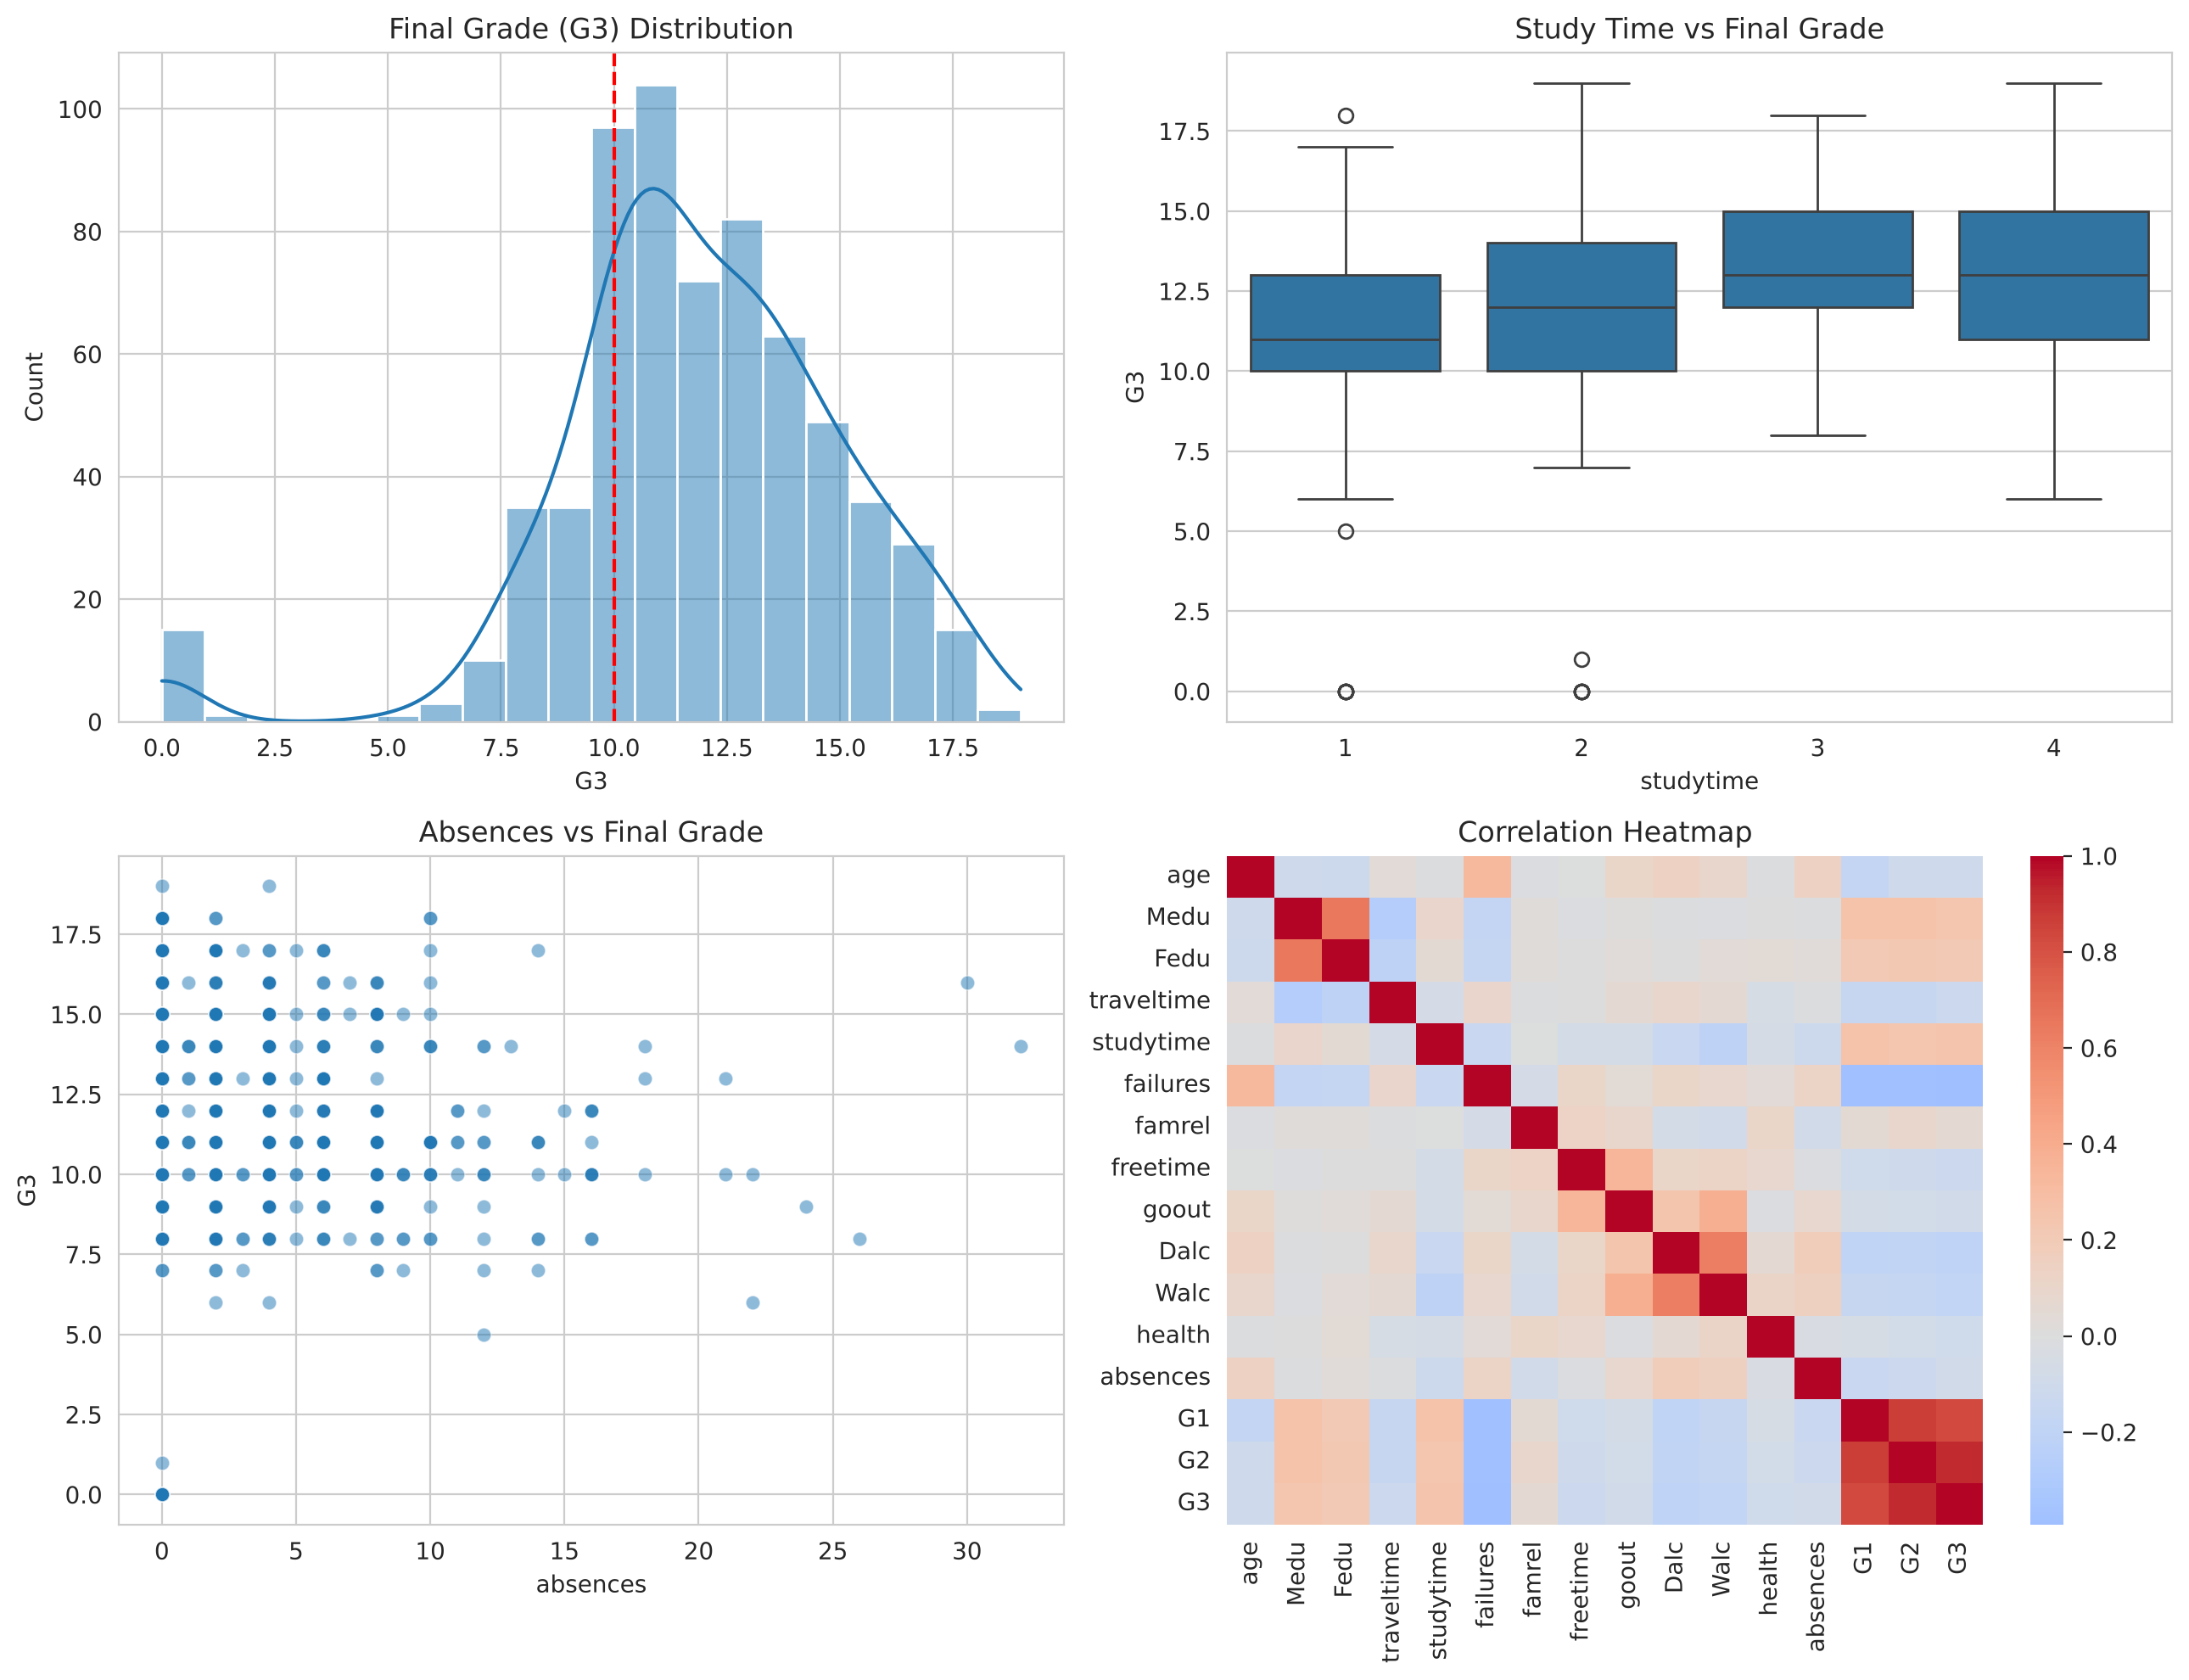

In [5]:
# Visualizations
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
sns.histplot(df['G3'], bins=20, kde=True, ax=ax[0,0]); ax[0,0].axvline(10, color='red', ls='--'); ax[0,0].set_title('Final Grade (G3) Distribution')
sns.boxplot(x='studytime', y='G3', data=df, ax=ax[0,1]); ax[0,1].set_title('Study Time vs Final Grade')
sns.scatterplot(x='absences', y='G3', data=df, alpha=0.5, ax=ax[1,0]); ax[1,0].set_title('Absences vs Final Grade')
sns.heatmap(num.corr(), cmap='coolwarm', center=0, ax=ax[1,1]); ax[1,1].set_title('Correlation Heatmap')
plt.tight_layout(); plt.savefig('eda_overview.png', dpi=150, bbox_inches='tight'); plt.show()

In [6]:
# Cleaning — remove exact duplicates, median/mode imputation if needed
df = df.drop_duplicates()
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == object: df[col] = df[col].fillna(df[col].mode()[0])
        else: df[col] = df[col].fillna(df[col].median())
df.to_csv('Datavera_Cleaned_Student_Data.csv', index=False)
print('Cleaned:', df.shape)

Cleaned: (649, 33)


In [7]:
# Preparation — exclude G1,G2 (early-warning: no later grades), one-hot encode categoricals
cat = list(df.select_dtypes(include=['object','string']).columns)
prepared = pd.get_dummies(df.drop(columns=['G1','G2']), columns=cat)
for col in prepared.columns:
    if prepared[col].dtype == bool: prepared[col] = prepared[col].astype(int)
prepared.to_csv('Datavera_Prepared_Model_Data.csv', index=False)
print('Prepared:', prepared.shape)
prepared.head()

Prepared: (649, 57)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,0,1,0,1,1,0,1,0
1,17,1,1,1,2,0,5,3,3,1,...,1,0,1,0,0,1,0,1,1,0
2,15,1,1,1,2,0,4,3,2,2,...,1,0,0,1,0,1,0,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,0,1,0,1,0,1,0,1,0,1
4,16,3,3,1,2,0,4,3,2,1,...,1,0,0,1,0,1,1,0,1,0


### Phase 1 notes
- **G1 and G2 are excluded** from the modeling features so the model predicts from background/behavioral data only — a genuine early-warning signal, not a shortcut from prior grades.
- Outputs: `Datavera_Cleaned_Student_Data.csv` (33 cols) and `Datavera_Prepared_Model_Data.csv` (57 cols, one-hot encoded).